In [1]:
import matplotlib.pyplot as plt

from nucleus_segmentation import (
    Observation,
    post_processing,
    pre_processing,
    segmentation,
    visualization,
)

In [2]:
output_folder = '../data/temp16/'
observation = Observation('../data/data_J0_S6.czi')
raw_data = observation.raw_data

CziMetadataSegmentData not found


In [3]:
visualization.save_image_view(
    raw_data,
    path=output_folder + '0_raw_data.png',
)

- resampling and cropping of the raw data

In [4]:
resampled_data = pre_processing.resample_isotropic(
    raw_data,
    observation.get_voxels_size(),
)
denoised_data = pre_processing.gaussian_denoise(resampled_data, ksize=2)
cropped_data = pre_processing.crop_background(denoised_data)

In [5]:
visualization.save_image_view(
    cropped_data,
    path=output_folder + '1_cropped.png',
)

In [6]:
visualization.save_image_view(
    cropped_data,
    path=output_folder + '1_cropped_top.png',
    camera_rotation=(0, 0, 0),
)

In [7]:
visualization.save_image_view(
    cropped_data,
    path=output_folder + '1_cropped_side.png',
    camera_rotation=(90, 0, -90),
)

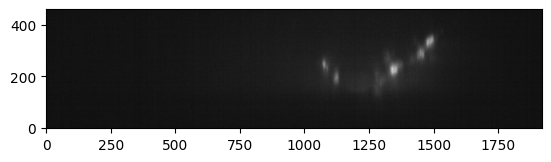

In [8]:
plt.imshow(resampled_data[:, :, 100], cmap='gray', origin='lower')

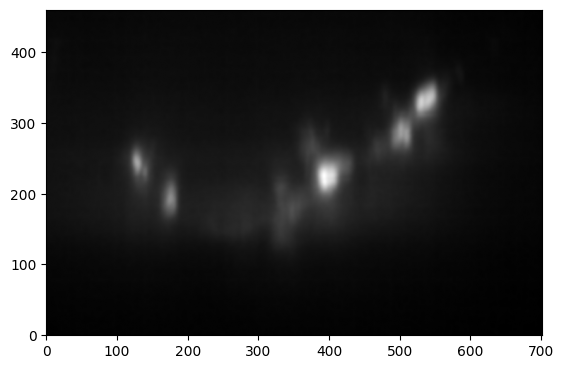

In [9]:
plt.imshow(cropped_data[:, :, 100], cmap='gray', origin='lower')

In [10]:
normalized_data = pre_processing.normalize_intensity_shift_method(
    cropped_data,
    cube_size=60,
    sigma=8,
    alpha=0.3,
)

In [11]:
visualization.save_image_view(
    normalized_data,
    path=output_folder + '2_normalized.png',
)

In [12]:
visualization.save_image_view(
    normalized_data,
    path=output_folder + '2_normalized_top.png',
    camera_rotation=(0, 0, 0),
)

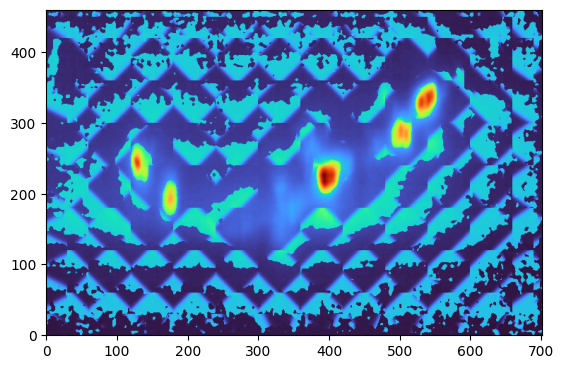

In [13]:
plt.imshow(normalized_data[:, :, 100], cmap='turbo', origin='lower')

In [14]:
segmented = segmentation.binarization_multiotsu(normalized_data, classes=3)

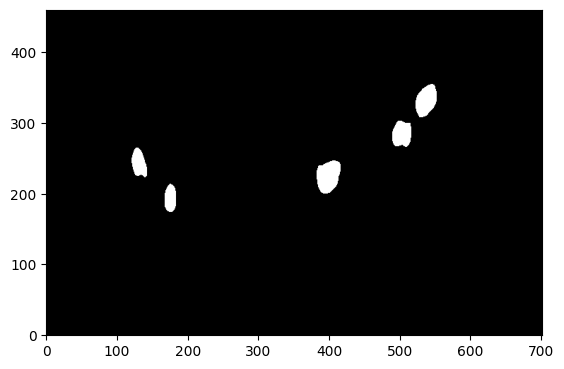

In [15]:
plt.imshow(segmented[:, :, 100], cmap='gray', origin='lower')

In [16]:
visualization.save_image_view(
    segmented,
    path=output_folder + '3_segmented_top.png',
    camera_rotation=(0, 0, 0),
)

In [17]:
segmented_clean = post_processing.remove_small_artefacts(segmented, max_size=1000)

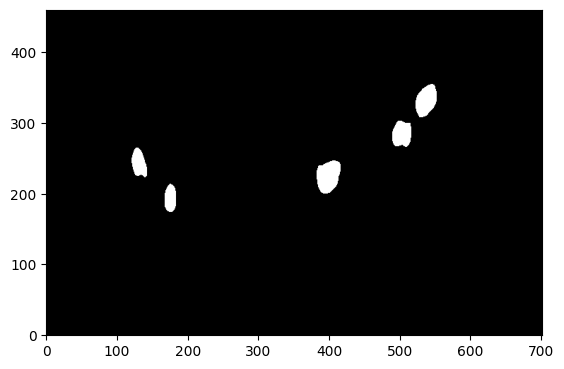

In [18]:
plt.imshow(segmented_clean[:, :, 100], cmap='gray', origin='lower')

In [19]:
visualization.save_image_view(
    segmented_clean,
    path=output_folder + '4_iso_segmented.png',
    mode='iso',
)

In [20]:
visualization.save_image_view(
    segmented_clean,
    path=output_folder + '4_iso_segmented_top.png',
    mode='iso',
    camera_rotation=(0, 0, 0),
)

In [21]:
visualization.save_image_view(
    segmented_clean,
    path=output_folder + '4_iso_segmented_side.png',
    mode='iso',
    camera_rotation=(90, 0, -90),
)

In [22]:
labelled = post_processing.get_labelled_cells(segmented_clean)

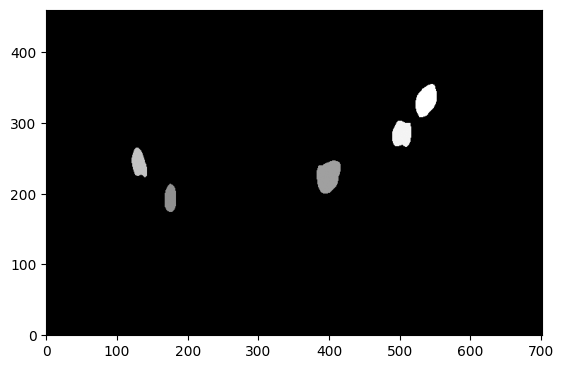

In [23]:
plt.imshow(labelled[:, :, 100], cmap='gray', origin='lower')

In [24]:
visualization.save_label_view(
    labelled,
    path=output_folder + '5_labelled.png',
    cmap='cividis',
)

In [25]:
visualization.save_label_view(
    labelled,
    path=output_folder + '5_labelled_top.png',
    cmap='cividis',
    camera_rotation=(0, 0, 0),
)

In [26]:
visualization.save_label_view(
    labelled,
    path=output_folder + '5_labelled_side.png',
    cmap='cividis',
    camera_rotation=(90, 0, -90),
)